In [ ]:
!pip install -q kaggle
from google.colab import files
files.upload()

In [4]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

1. HAM10000




In [5]:
!mkdir -p /content/HAM10000

!kaggle datasets download \
    -d kmader/skin-cancer-mnist-ham10000 \
    -p /content/HAM10000

Dataset URL: https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000
License(s): CC-BY-NC-SA-4.0
100% 5.20G/5.20G [02:14<00:00, 41.6MB/s]



2. Extracting Dataset


In [6]:
import zipfile
import os

zip_path = "/content/HAM10000/skin-cancer-mnist-ham10000.zip"
extract_path = "/content/HAM10000/data"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)


# Skin Lesion Classification Using Deep Learning

## Project Overview

This project explores the application of deep learning and transfer learning for classifying dermatoscopic skin-lesion images using the HAM10000 dataset.

The project uses EfficientNetB0, a convolutional neural network pretrained on ImageNet, to classify images into seven diagnostic categories.

## Project Objectives

- Explore and analyse the HAM10000 dataset.
- Develop an image preprocessing pipeline.
- Address class imbalance in the dataset.
- Implement transfer learning using EfficientNetB0.
- Fine-tune the model for skin-lesion classification.
- Evaluate model performance using accuracy, precision, recall, F1-score and a confusion matrix.
- Analyse the limitations and challenges of multiclass medical image classification.

## Dataset

HAM10000 contains 10,015 dermatoscopic images across seven diagnostic categories.

## Model

EfficientNetB0 with ImageNet pretrained weights.

3. Environment Setup and Library Imports

In [7]:
import os
import glob
import random
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


4. Dataset Setup and File Paths

In [9]:
DATA_PATH = "/content/HAM10000/data"

IMAGE_DIRS = [
    os.path.join(DATA_PATH, "HAM10000_images_part_1"),
    os.path.join(DATA_PATH, "HAM10000_images_part_2")
]

METADATA_PATH = os.path.join(
    DATA_PATH,
    "HAM10000_metadata.csv"
)

for folder in IMAGE_DIRS:
    print(folder, "Exists:", os.path.exists(folder))

print("Metadata exists:", os.path.exists(METADATA_PATH))

/content/HAM10000/data/HAM10000_images_part_1 Exists: True
/content/HAM10000/data/HAM10000_images_part_2 Exists: True
Metadata exists: True


5. Dataset Loading and Exploration

In [10]:
metadata = pd.read_csv(METADATA_PATH)
print("Dataset shape:", metadata.shape)

print("\nDataset columns:")
print(metadata.columns.tolist())

print("\nFirst five records:")
display(metadata.head())

print("\nMissing values:")
print(metadata.isnull().sum())

Dataset shape: (10015, 7)

Dataset columns:
['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']

First five records:


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear



Missing values:
lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
dtype: int64


6. Class Distribution Analysis

       Image Count  Percentage
dx                            
nv            6705       66.95
mel           1113       11.11
bkl           1099       10.97
bcc            514        5.13
akiec          327        3.27
vasc           142        1.42
df             115        1.15


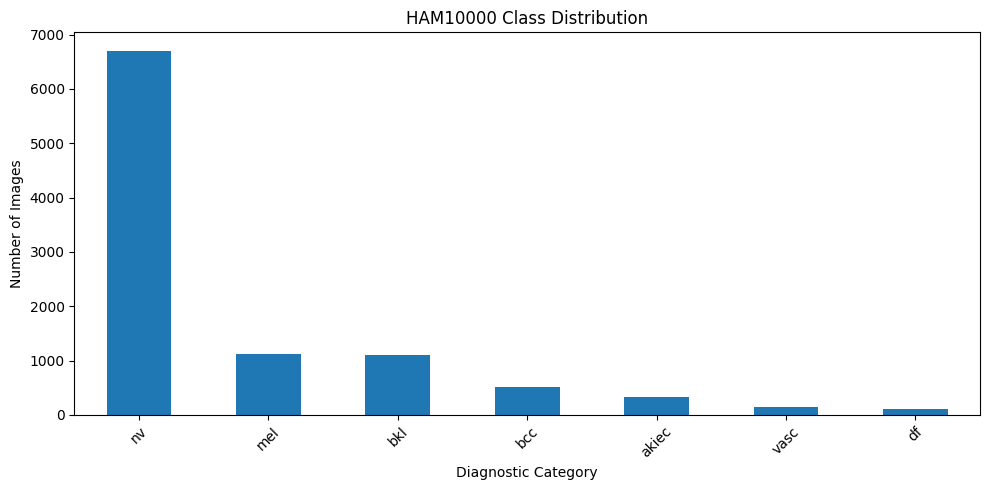

<Figure size 640x480 with 0 Axes>

In [79]:
class_counts = metadata["dx"].value_counts()


class_percentages = (
    metadata["dx"].value_counts(normalize=True) * 100
)

distribution = pd.DataFrame({
    "Image Count": class_counts,
    "Percentage": class_percentages.round(2)
})

print(distribution)


plt.figure(figsize=(10, 5))

class_counts.plot(kind="bar")

plt.title("HAM10000 Class Distribution")
plt.xlabel("Diagnostic Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
plt.savefig("class_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()

7. Image File Verification

In [12]:
image_paths = []

for folder in IMAGE_DIRS:
    image_paths.extend(
        glob.glob(os.path.join(folder, "*.jpg"))
    )

image_path_map = {
    os.path.splitext(os.path.basename(path))[0]: path
    for path in image_paths
}

metadata_ids = set(metadata["image_id"])
image_ids = set(image_path_map.keys())

print("Total image files:", len(image_paths))
print("Unique image IDs:", len(image_ids))
print("Metadata records:", len(metadata))
print("Images missing from metadata:", len(image_ids - metadata_ids))
print("Metadata records missing images:", len(metadata_ids - image_ids))
print("Duplicate metadata image IDs:", metadata["image_id"].duplicated().sum())

Total image files: 10015
Unique image IDs: 10015
Metadata records: 10015
Images missing from metadata: 0
Metadata records missing images: 0
Duplicate metadata image IDs: 0


8. Image Path Mapping

In [13]:
metadata["path"] = metadata["image_id"].map(image_path_map)

print("Missing image paths:", metadata["path"].isnull().sum())

display(metadata.head())

Missing image paths: 0


,lesion_id,image_id,dx,dx_type,age,sex,localization,path
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/content/HAM10000/data/HAM10000_images_part_1/...
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/content/HAM10000/data/HAM10000_images_part_1/...
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/content/HAM10000/data/HAM10000_images_part_1/...
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/content/HAM10000/data/HAM10000_images_part_1/...
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/content/HAM10000/data/HAM10000_images_part_2/...


9. Sample Image Visualisation

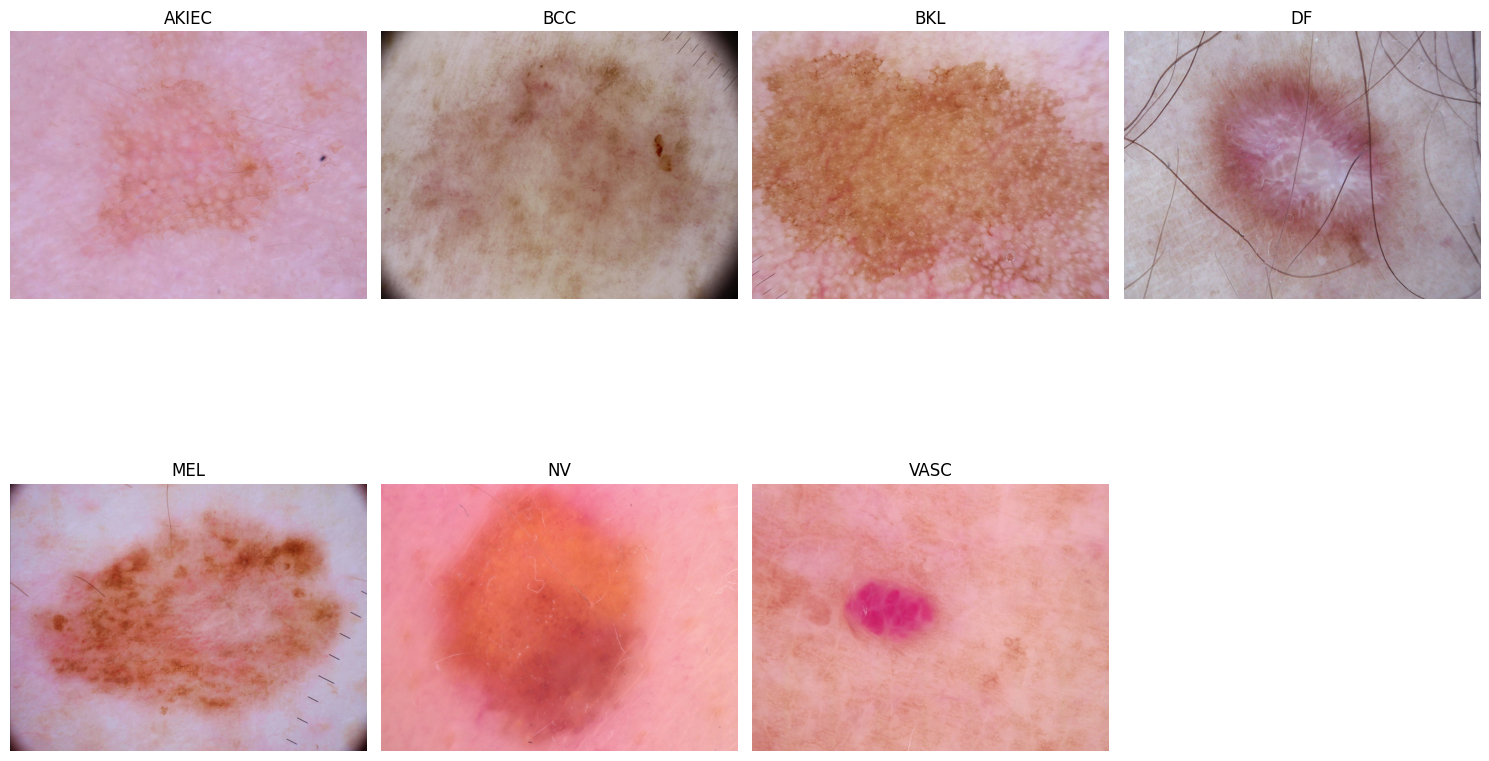

<Figure size 640x480 with 0 Axes>

In [80]:
classes = sorted(metadata["dx"].unique())

plt.figure(figsize=(15, 10))

for i, class_name in enumerate(classes):
    sample = metadata[metadata["dx"] == class_name].sample(
        n=1,
        random_state=SEED
    )

    image_path = sample.iloc[0]["path"]

    image = Image.open(image_path)

    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.title(class_name.upper())
    plt.axis("off")

plt.tight_layout()
plt.show()
plt.savefig("class_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()

10. Lesion-Level Analysis

In [16]:
lesion_counts = metadata["lesion_id"].value_counts()

print("Total unique lesions:", metadata["lesion_id"].nunique())

print("\nLesions with multiple images:")
print((lesion_counts > 1).sum())

print("\nMaximum images per lesion:")
print(lesion_counts.max())

labels_per_lesion = metadata.groupby("lesion_id")["dx"].nunique()

print("\nLesions with multiple diagnostic labels:")
print((labels_per_lesion > 1).sum())

Total unique lesions: 7470

Lesions with multiple images:
1956

Maximum images per lesion:
6

Lesions with multiple diagnostic labels:
0


11. Train, Validation and Test Split

In [17]:
splitter_test = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

train_val_indices, test_indices = next(
    splitter_test.split(
        metadata,
        metadata["dx"],
        groups=metadata["lesion_id"]
    )
)

train_val_df = metadata.iloc[train_val_indices].copy()
test_df = metadata.iloc[test_indices].copy()

splitter_val = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

train_indices, val_indices = next(
    splitter_val.split(
        train_val_df,
        train_val_df["dx"],
        groups=train_val_df["lesion_id"]
    )
)

train_df = train_val_df.iloc[train_indices].copy()
val_df = train_val_df.iloc[val_indices].copy()

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

Training images: 6409
Validation images: 1592
Testing images: 2014


In [18]:
train_lesions = set(train_df["lesion_id"])
val_lesions = set(val_df["lesion_id"])
test_lesions = set(test_df["lesion_id"])

print("Train-validation overlap:", len(train_lesions & val_lesions))
print("Train-test overlap:", len(train_lesions & test_lesions))
print("Validation-test overlap:", len(val_lesions & test_lesions))

Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0


In [19]:
print("TRAINING DISTRIBUTION")
display(train_df["dx"].value_counts())

print("VALIDATION DISTRIBUTION")
display(val_df["dx"].value_counts())

print("TEST DISTRIBUTION")
display(test_df["dx"].value_counts())

TRAINING DISTRIBUTION


,count
dx,
nv,4248
bkl,730
mel,728
bcc,343
akiec,208
df,79
vasc,73


VALIDATION DISTRIBUTION


,count
dx,
nv,1094
bkl,164
mel,163
bcc,71
akiec,51
vasc,35
df,14


TEST DISTRIBUTION


,count
dx,
nv,1363
mel,222
bkl,205
bcc,100
akiec,68
vasc,34
df,22


12. Image Preprocessing Configuration

In [20]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = len(train_df["dx"].unique())

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", NUM_CLASSES)

class_names = sorted(train_df["dx"].unique())

print("Classes:", class_names)

Image size: (224, 224)
Batch size: 32
Number of classes: 7
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']


13. Image Dataset Creation

In [21]:
class_to_index = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

print("Class mapping:", class_to_index)

Class mapping: {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}


In [22]:
def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, label

In [23]:
def create_dataset(dataframe, training=False):
    image_paths = dataframe["path"].values

    labels = dataframe["dx"].map(class_to_index).values

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

In [24]:
train_dataset = create_dataset(train_df, training=True)
val_dataset = create_dataset(val_df)
test_dataset = create_dataset(test_df)

print("Datasets created successfully.")

Datasets created successfully.


14. Image Pipeline Verification

In [25]:
images, labels = next(iter(train_dataset))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Minimum pixel value:", tf.reduce_min(images).numpy())
print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>
Minimum pixel value: 0.38220072
Maximum pixel value: 255.0


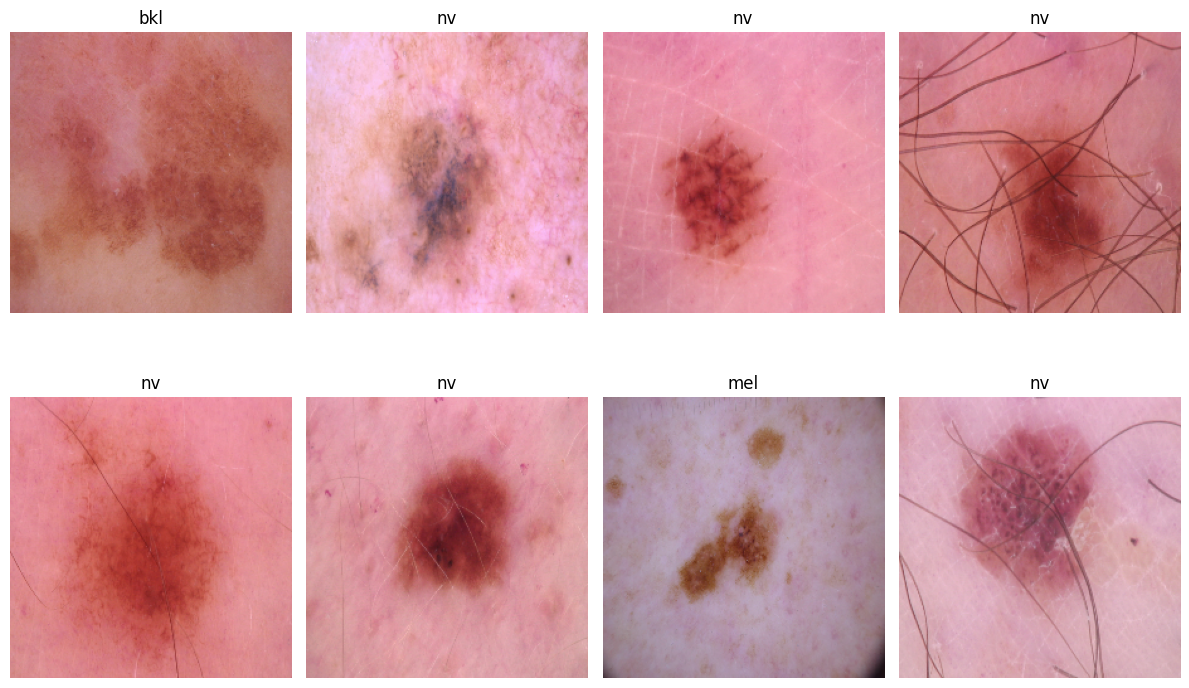

<Figure size 640x480 with 0 Axes>

In [74]:
plt.figure(figsize=(12, 8))

for i in range(8):
    plt.subplot(2, 4, i + 1)

    plt.imshow(
        tf.cast(images[i], tf.uint8).numpy()
    )

    label_index = labels[i].numpy()
    plt.title(class_names[label_index])
    plt.axis("off")

plt.tight_layout()
plt.show()
plt.savefig("class_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()

15. Class Imbalance Handling

In [27]:
class_counts = train_df["dx"].value_counts()

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array(class_names),
    y=train_df["dx"]
)

class_weights = {
    index: weight
    for index, weight in enumerate(weights)
}

print("Class counts:")
print(class_counts)

print("\nClass weights:")
print(class_weights)

Class counts:
dx
nv       4248
bkl       730
mel       728
bcc       343
akiec     208
df         79
vasc       73
Name: count, dtype: int64

Class weights:
{0: np.float64(4.401785714285714), 1: np.float64(2.669304456476468), 2: np.float64(1.2542074363992173), 3: np.float64(11.589511754068717), 4: np.float64(1.2576530612244898), 5: np.float64(0.21552999730965833), 6: np.float64(12.542074363992173)}


16. Data Augmentation

In [28]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.1)
])

print("Data augmentation created successfully.")

Data augmentation created successfully.


17. EfficientNet80 Transfer Learning

In [29]:
base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

print("EfficientNetB0 loaded successfully.")
print("Total layers:", len(base_model.layers))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
EfficientNetB0 loaded successfully.
Total layers: 238


18. Model Architecture

In [30]:
inputs = keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.4)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = keras.Model(inputs, outputs)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,379,306 (16.71 MB)

 Trainable params: 329,735 (1.26 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

19. Model Compilation

In [31]:
model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


20. Training Callbacks

In [32]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=0.00001
    ),

    keras.callbacks.ModelCheckpoint(
        "best_skin_lesion_model.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

print("Training callbacks configured.")

Training callbacks configured.


21. Initial Model Training

In [33]:
EPOCHS = 15

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 68s 255ms/step - accuracy: 0.3926 - loss: 1.5922 - val_accuracy: 0.3995 - val_loss: 1.3713 - learning_rate: 0.0010
Epoch 2/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 45s 223ms/step - accuracy: 0.4990 - loss: 1.2457 - val_accuracy: 0.4912 - val_loss: 1.2516 - learning_rate: 0.0010
Epoch 3/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 43s 211ms/step - accuracy: 0.5355 - loss: 1.1204 - val_accuracy: 0.5540 - val_loss: 1.0989 - learning_rate: 0.0010
Epoch 4/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 41s 203ms/step - accuracy: 0.5661 - loss: 1.0742 - val_accuracy: 0.5509 - val_loss: 1.0945 - learning_rate: 0.0010
Epoch 5/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 41s 205ms/step - accuracy: 0.5812 - loss: 1.0261 - val_accuracy: 0.5440 - val_loss: 1.0932 - learning_rate: 0.0010
Epoch 6/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 43s 211ms/step - accuracy: 0.5931 - loss: 0.9647 - val_accuracy: 0.6671 - val_loss: 0.8520 - learning_rate: 0.0010
Epoch 7/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 43s 214ms/step - accuracy: 0.5

22. Initial Training Performance

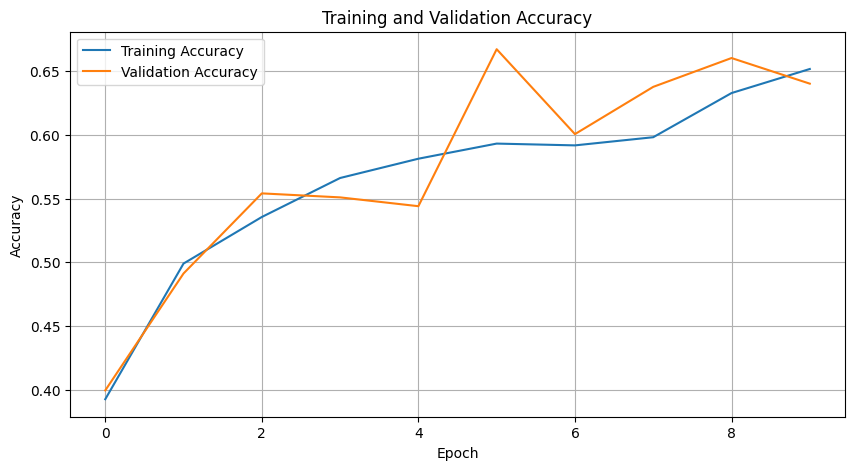

<Figure size 640x480 with 0 Axes>

In [73]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()
plt.savefig("class_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()

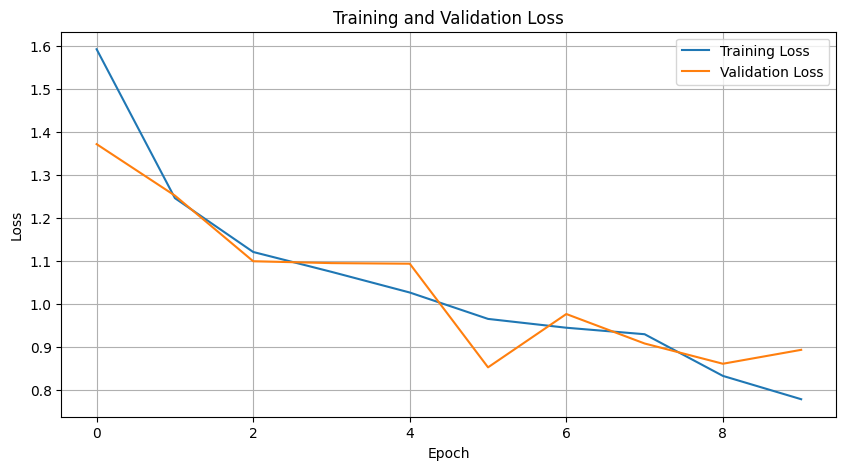

<Figure size 640x480 with 0 Axes>

In [72]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()
plt.savefig("class_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [36]:
print("Best validation accuracy:",
      max(history.history["val_accuracy"]))

print("Best validation loss:",
      min(history.history["val_loss"]))

print("Epochs completed:",
      len(history.history["loss"]))

Best validation accuracy: 0.6670854091644287
Best validation loss: 0.8520445823669434
Epochs completed: 10


23. EfficientNetB0 Fine-Tuning

In [37]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

trainable_parameters = sum(
    np.prod(variable.shape)
    for variable in model.trainable_weights
)

print("Trainable parameters:", trainable_parameters)

Trainable parameters: 1813095


In [38]:
model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fine-tuning model compiled.")

Fine-tuning model compiled.


In [39]:
FINE_TUNE_EPOCHS = 15

fine_tune_history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=FINE_TUNE_EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 64s 240ms/step - accuracy: 0.6247 - loss: 0.8818 - val_accuracy: 0.6351 - val_loss: 0.8982 - learning_rate: 1.0000e-05
Epoch 2/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 41s 205ms/step - accuracy: 0.6332 - loss: 0.8339 - val_accuracy: 0.6438 - val_loss: 0.8830 - learning_rate: 1.0000e-05
Epoch 3/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 41s 205ms/step - accuracy: 0.6464 - loss: 0.8038 - val_accuracy: 0.6376 - val_loss: 0.8960 - learning_rate: 1.0000e-05
Epoch 4/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 43s 214ms/step - accuracy: 0.6521 - loss: 0.7981 - val_accuracy: 0.6388 - val_loss: 0.8959 - learning_rate: 1.0000e-05


In [41]:
fine_tune_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=0.000001
    ),

    keras.callbacks.ModelCheckpoint(
        "best_fine_tuned_model.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

In [42]:
model = keras.models.load_model(
    "best_skin_lesion_model.keras"
)

base_model = model.get_layer("efficientnetb0")
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Best frozen model restored and ready for fine-tuning.")

Best frozen model restored and ready for fine-tuning.


In [43]:
fine_tune_history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=15,
    class_weight=class_weights,
    callbacks=fine_tune_callbacks
)

Epoch 1/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 69s 286ms/step - accuracy: 0.6215 - loss: 0.8926 - val_accuracy: 0.6394 - val_loss: 0.8886 - learning_rate: 1.0000e-05
Epoch 2/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 44s 219ms/step - accuracy: 0.6363 - loss: 0.8316 - val_accuracy: 0.6149 - val_loss: 0.9291 - learning_rate: 1.0000e-05
Epoch 3/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 43s 214ms/step - accuracy: 0.6318 - loss: 0.8234 - val_accuracy: 0.6256 - val_loss: 0.9240 - learning_rate: 1.0000e-05
Epoch 4/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 84s 226ms/step - accuracy: 0.6311 - loss: 0.8027 - val_accuracy: 0.6394 - val_loss: 0.8862 - learning_rate: 2.0000e-06
Epoch 5/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 43s 214ms/step - accuracy: 0.6514 - loss: 0.7783 - val_accuracy: 0.6376 - val_loss: 0.8912 - learning_rate: 2.0000e-06
Epoch 6/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 84s 224ms/step - accuracy: 0.6558 - loss: 0.7678 - val_accuracy: 0.6413 - val_loss: 0.8860 - learning_rate: 2.0000e-06
Epoch 7/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 42s 20

In [44]:
print("Fine-tuning epochs:",
      len(fine_tune_history.history["loss"]))

print("Best validation accuracy:",
      max(fine_tune_history.history["val_accuracy"]))

print("Best validation loss:",
      min(fine_tune_history.history["val_loss"]))

Fine-tuning epochs: 15
Best validation accuracy: 0.641331672668457
Best validation loss: 0.8747523427009583


In [45]:
frozen_model = keras.models.load_model(
    "best_skin_lesion_model.keras"
)

fine_tuned_model = keras.models.load_model(
    "best_fine_tuned_model.keras"
)

frozen_results = frozen_model.evaluate(
    val_dataset,
    verbose=0
)

fine_tuned_results = fine_tuned_model.evaluate(
    val_dataset,
    verbose=0
)

print("Frozen model:")
print("Loss:", frozen_results[0])
print("Accuracy:", frozen_results[1])

print("\nFine-tuned model:")
print("Loss:", fine_tuned_results[0])
print("Accuracy:", fine_tuned_results[1])

Frozen model:
Loss: 0.8520445823669434
Accuracy: 0.6670854091644287

Fine-tuned model:
Loss: 0.8747523427009583
Accuracy: 0.641331672668457


In [46]:
if frozen_results[0] <= fine_tuned_results[0]:
    best_model = frozen_model
    selected_model_name = "Frozen EfficientNetB0"
else:
    best_model = fine_tuned_model
    selected_model_name = "Fine-tuned EfficientNetB0"

print("Selected model:", selected_model_name)

Selected model: Frozen EfficientNetB0


24. Final Test Set Evaluation

In [47]:
y_prob = best_model.predict(test_dataset)

y_pred = np.argmax(y_prob, axis=1)

y_true = test_df["dx"].map(class_to_index).values

print("Predictions generated successfully.")
print("Number of test images:", len(y_true))

63/63 ━━━━━━━━━━━━━━━━━━━━ 19s 237ms/step
Predictions generated successfully.
Number of test images: 2014


25. Classification Performance Metrics

In [48]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

test_accuracy = accuracy_score(y_true, y_pred)

balanced_acc = balanced_accuracy_score(
    y_true, y_pred
)

macro_precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

macro_recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

macro_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

weighted_f1 = f1_score(
    y_true, y_pred, average="weighted", zero_division=0
)

print("TEST SET RESULTS")
print("-----------------------------")
print("Accuracy:", round(test_accuracy, 4))
print("Balanced Accuracy:", round(balanced_acc, 4))
print("Macro Precision:", round(macro_precision, 4))
print("Macro Recall:", round(macro_recall, 4))
print("Macro F1-score:", round(macro_f1, 4))
print("Weighted F1-score:", round(weighted_f1, 4))

TEST SET RESULTS
-----------------------------
Accuracy: 0.6534
Balanced Accuracy: 0.534
Macro Precision: 0.448
Macro Recall: 0.534
Macro F1-score: 0.4503
Weighted F1-score: 0.6923


In [49]:
print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=class_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

       akiec       0.40      0.47      0.43        68
         bcc       0.58      0.38      0.46       100
         bkl       0.53      0.43      0.47       205
          df       0.09      0.41      0.15        22
         mel       0.30      0.65      0.41       222
          nv       0.95      0.72      0.82      1363
        vasc       0.29      0.68      0.41        34

    accuracy                           0.65      2014
   macro avg       0.45      0.53      0.45      2014
weighted avg       0.77      0.65      0.69      2014



26. Confusion Matrix

<Figure size 1000x800 with 0 Axes>

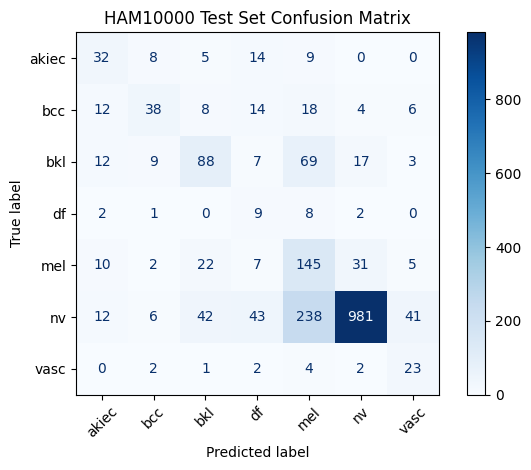

In [50]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

plt.figure(figsize=(10, 8))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("HAM10000 Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

In [53]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1, support = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    zero_division=0
)

class_results = pd.DataFrame({
    "Class": class_names,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "Support": support
})

class_results[["Precision", "Recall", "F1-score"]] = (
    class_results[["Precision", "Recall", "F1-score"]].round(4)
)

print(class_results.to_string(index=False))

Class  Precision  Recall  F1-score  Support
akiec     0.4000  0.4706    0.4324       68
  bcc     0.5758  0.3800    0.4578      100
  bkl     0.5301  0.4293    0.4744      205
   df     0.0938  0.4091    0.1525       22
  mel     0.2953  0.6532    0.4067      222
   nv     0.9460  0.7197    0.8175     1363
 vasc     0.2949  0.6765    0.4107       34


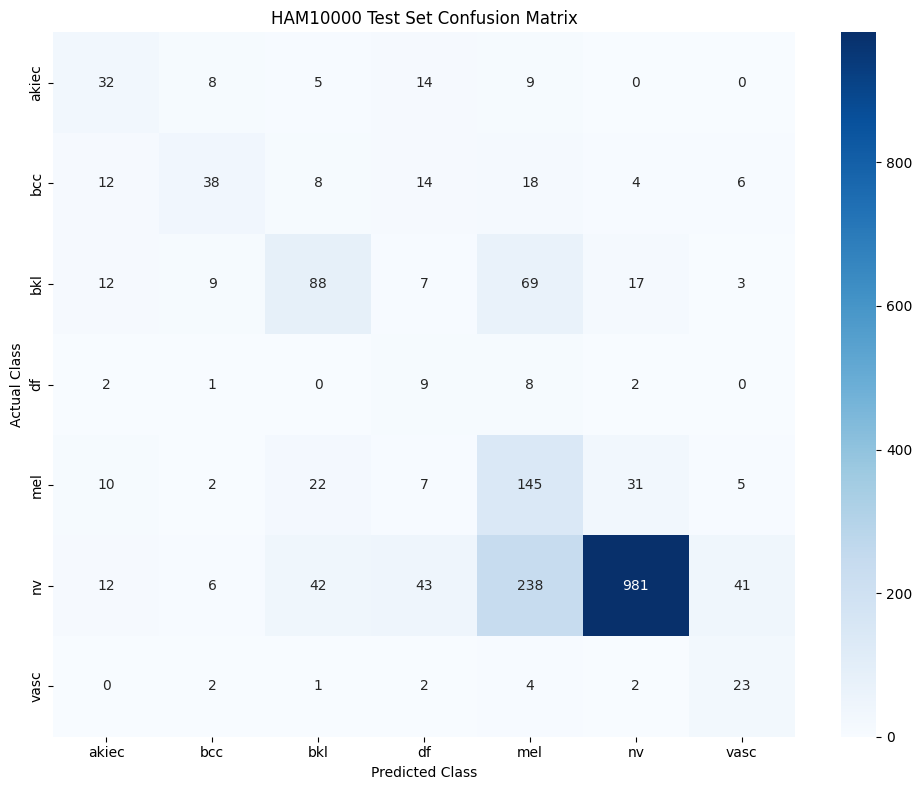

<Figure size 640x480 with 0 Axes>

In [71]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("HAM10000 Test Set Confusion Matrix")
plt.tight_layout()
plt.show()
plt.savefig("class_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()

27. Multi-class ROC AUC analysis

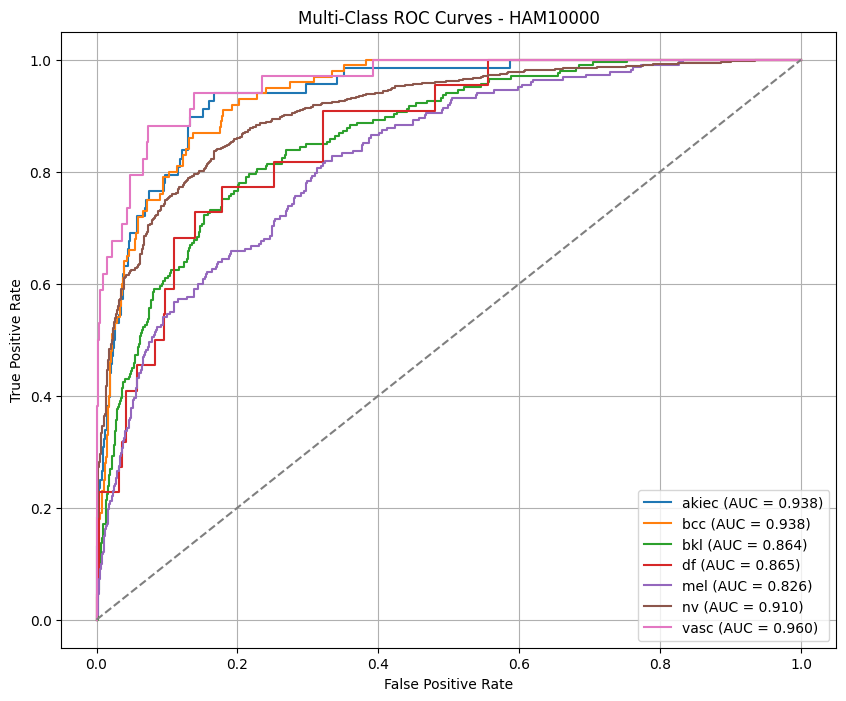

<Figure size 640x480 with 0 Axes>

In [69]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score
import matplotlib.pyplot as plt

y_true_binary = label_binarize(
    y_true,
    classes=list(range(NUM_CLASSES))
)

plt.figure(figsize=(10, 8))

for i, class_name in enumerate(class_names):

    fpr, tpr, thresholds = roc_curve(
        y_true_binary[:, i],
        y_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {roc_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multi-Class ROC Curves - HAM10000")
plt.legend()
plt.grid()
plt.show()
plt.savefig("class_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [56]:
macro_roc_auc = roc_auc_score(
    y_true,
    y_prob,
    multi_class="ovr",
    average="macro"
)

weighted_roc_auc = roc_auc_score(
    y_true,
    y_prob,
    multi_class="ovr",
    average="weighted"
)

print("Macro ROC-AUC:", round(macro_roc_auc, 4))
print("Weighted ROC-AUC:", round(weighted_roc_auc, 4))

Macro ROC-AUC: 0.9003
Weighted ROC-AUC: 0.8989


28. Prediction confidence analysis

In [57]:
prediction_confidence = np.max(y_prob, axis=1)

confidence_df = pd.DataFrame({
    "Actual Class": [class_names[i] for i in y_true],
    "Predicted Class": [class_names[i] for i in y_pred],
    "Confidence": prediction_confidence,
    "Correct": (y_true == y_pred)
})

print("Average confidence:",
      round(prediction_confidence.mean(), 4))

print("Average confidence for correct predictions:",
      round(confidence_df[confidence_df["Correct"]]["Confidence"].mean(), 4))

print("Average confidence for incorrect predictions:",
      round(confidence_df[~confidence_df["Correct"]]["Confidence"].mean(), 4))

Average confidence: 0.6407
Average confidence for correct predictions: 0.7064
Average confidence for incorrect predictions: 0.5168


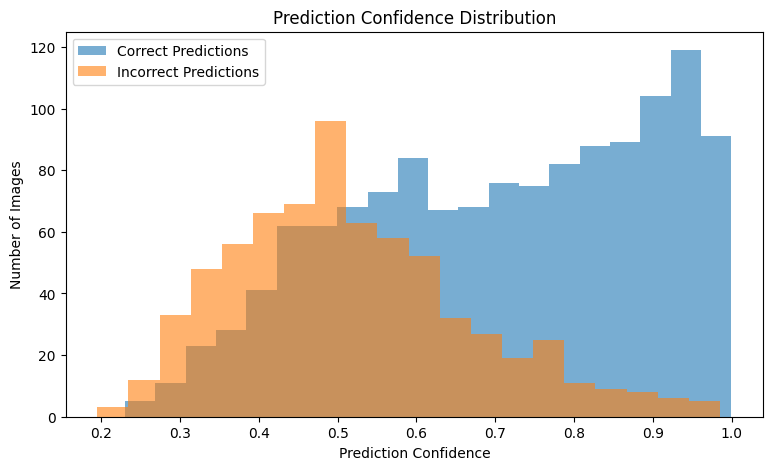

In [58]:
plt.figure(figsize=(9, 5))

plt.hist(
    confidence_df[confidence_df["Correct"]]["Confidence"],
    bins=20,
    alpha=0.6,
    label="Correct Predictions"
)

plt.hist(
    confidence_df[~confidence_df["Correct"]]["Confidence"],
    bins=20,
    alpha=0.6,
    label="Incorrect Predictions"
)

plt.xlabel("Prediction Confidence")
plt.ylabel("Number of Images")
plt.title("Prediction Confidence Distribution")
plt.legend()
plt.show()

29. Confidence calibration

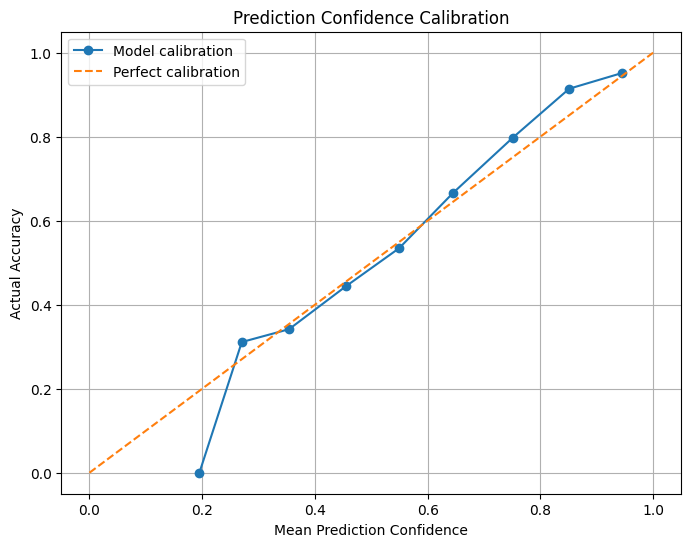

<Figure size 640x480 with 0 Axes>

In [70]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import log_loss

confidence = np.max(y_prob, axis=1)

correct_predictions = (y_true == y_pred).astype(int)

fraction_positive, mean_predicted = calibration_curve(
    correct_predictions,
    confidence,
    n_bins=10,
    strategy="uniform"
)

plt.figure(figsize=(8, 6))

plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    label="Model calibration"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean Prediction Confidence")
plt.ylabel("Actual Accuracy")
plt.title("Prediction Confidence Calibration")
plt.legend()
plt.grid()
plt.show()
plt.savefig("class_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [60]:
test_log_loss = log_loss(
    y_true,
    y_prob,
    labels=list(range(NUM_CLASSES))
)

print("Test Log Loss:", round(test_log_loss, 4))

Test Log Loss: 0.8998


In [62]:
error_df = pd.DataFrame({
    "Actual": [class_names[i] for i in y_true],
    "Predicted": [class_names[i] for i in y_pred],
    "Confidence": np.max(y_prob, axis=1),
    "Correct": y_true == y_pred
})

incorrect_df = error_df[error_df["Correct"] == False]

print("Total test images:", len(error_df))
print("Correct predictions:", error_df["Correct"].sum())
print("Incorrect predictions:", len(incorrect_df))

print("\nMost common classification errors:")

error_summary = (
    incorrect_df.groupby(["Actual", "Predicted"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

print(error_summary.head(15))

Total test images: 2014
Correct predictions: 1316
Incorrect predictions: 698

Most common classification errors:
   Actual Predicted  Count
30     nv       mel    238
13    bkl       mel     69
29     nv        df     43
28     nv       bkl     42
31     nv      vasc     41
24    mel        nv     31
22    mel       bkl     22
7     bcc       mel     18
14    bkl        nv     17
2   akiec        df     14
6     bcc        df     14
10    bkl     akiec     12
4     bcc     akiec     12
26     nv     akiec     12
20    mel     akiec     10


In [64]:
class_error_analysis = (
    error_df.groupby("Actual")
    .agg(
        Total_Images=("Correct", "count"),
        Correct=("Correct", "sum")
    )
)

class_error_analysis["Incorrect"] = (
    class_error_analysis["Total_Images"]
    - class_error_analysis["Correct"]
)

class_error_analysis["Error_Rate"] = (
    class_error_analysis["Incorrect"]
    / class_error_analysis["Total_Images"]
)

class_error_analysis["Error_Rate"] = (
    class_error_analysis["Error_Rate"] * 100
).round(2)

print(class_error_analysis)

        Total_Images  Correct  Incorrect  Error_Rate
Actual                                              
akiec             68       32         36       52.94
bcc              100       38         62       62.00
bkl              205       88        117       57.07
df                22        9         13       59.09
mel              222      145         77       34.68
nv              1363      981        382       28.03
vasc              34       23         11       32.35


NV predicted as MEL: 238


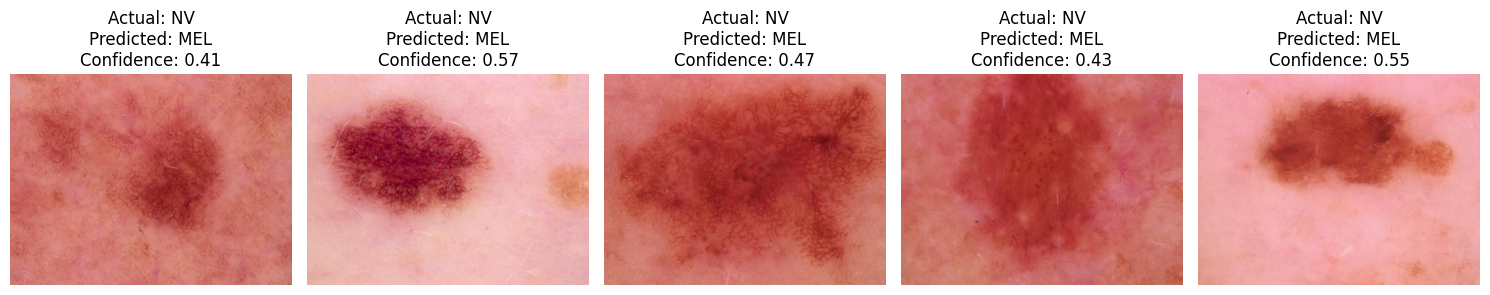

In [65]:
nv_to_mel = error_df[
    (error_df["Actual"] == "nv") &
    (error_df["Predicted"] == "mel")
].copy()

nv_to_mel["Image_Path"] = test_df.loc[
    nv_to_mel.index, "path"
]

print("NV predicted as MEL:", len(nv_to_mel))

plt.figure(figsize=(15, 8))

for i, (_, row) in enumerate(nv_to_mel.head(5).iterrows()):
    image = Image.open(row["Image_Path"]).convert("RGB")

    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.title(
        f"Actual: NV\nPredicted: MEL\nConfidence: {row['Confidence']:.2f}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [66]:
import os
import json
import numpy as np
import pandas as pd

# Create project output folder
os.makedirs("/content/skin_lesion_project", exist_ok=True)

# Save selected model
best_model.save(
    "/content/skin_lesion_project/efficientnetb0_skin_lesion.keras"
)

# Save evaluation metrics
final_results = {
    "selected_model": selected_model_name,
    "test_images": int(len(y_true)),
    "accuracy": float(test_accuracy),
    "balanced_accuracy": float(balanced_acc),
    "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall),
    "macro_f1": float(macro_f1),
    "weighted_f1": float(weighted_f1),
    "macro_roc_auc": float(macro_roc_auc),
    "weighted_roc_auc": float(weighted_roc_auc),
    "test_log_loss": float(test_log_loss)
}

with open(
    "/content/skin_lesion_project/evaluation_results.json",
    "w"
) as file:
    json.dump(final_results, file, indent=4)

# Save class-wise metrics
class_results.to_csv(
    "/content/skin_lesion_project/class_wise_results.csv",
    index=False
)

# Save classification errors
error_summary.to_csv(
    "/content/skin_lesion_project/classification_errors.csv",
    index=False
)

print("Project model and evaluation results saved.")

Project model and evaluation results saved.


In [67]:
readme = """
# HAM10000 Skin Lesion Classification

## Overview
A seven-class skin lesion image classification project using
transfer learning with EfficientNetB0 and the HAM10000 dataset.

## Methodology
- Dataset: HAM10000 (10,015 dermatoscopic images)
- Image resolution: 224 x 224
- Architecture: EfficientNetB0 (ImageNet pretrained)
- Classification: Seven diagnostic categories
- Data augmentation and class-weighted training
- Train/validation/test separation using lesion-level grouping
- Frozen backbone compared with fine-tuning

## Final Model
The frozen EfficientNetB0 model was selected based on
validation loss.

## Test Results
- Accuracy: 65.34%
- Balanced Accuracy: 53.40%
- Macro F1: 45.03%
- Weighted F1: 69.23%
- Macro ROC-AUC: 90.03%
- Weighted ROC-AUC: 89.89%
- Log Loss: 0.8998

## Key Finding
The model achieved relatively high ROC-AUC but lower
macro F1, indicating a gap between class discrimination
and final seven-class classification performance.

The most frequent classification error was NV predicted
as MEL (238 cases).

## Limitations
- Class imbalance affects minority-class performance.
- The dataset is limited to HAM10000.
- Results do not establish clinical validity or suitability
  for medical diagnosis.
- External validation is required before any real-world use.

## Technologies
Python, TensorFlow, Keras, EfficientNetB0, NumPy,
Pandas, Matplotlib, Scikit-learn.

## Dataset
HAM10000: Human Against Machine with 10000 training images.
Dataset source: https://doi.org/10.1038/sdata.2018.161
"""

with open(
    "/content/skin_lesion_project/README.md",
    "w"
) as file:
    file.write(readme)

print("README created.")

README created.


In [68]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/HAM10000_Skin_Lesion_Project",
    "zip",
    "/content/skin_lesion_project"
)

files.download("/content/HAM10000_Skin_Lesion_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>